# Projeto 2 - Task 1: Construção das séries temporais, análise exploratória e protocolo de previsão

**Objetivo do projeto:** prever o número de sessões de carregamento de VE que começam em cada uma das próximas 24 horas, ao nível da rede e de cada distrito.

## Índice

| Secção | Subsecção |
|---|---|
| **1. Preparação dos dados** | 1.1 Setup e carregamento |
| | 1.2 Auditoria da qualidade dos dados |
| | 1.3 Construção das séries horárias |
| **2. Análise exploratória** | 2.1 Evolução e tendência |
| | 2.2 Sazonalidade diária e semanal |
| | 2.3 Decomposição STL |
| | 2.4 Autocorrelação (ACF / PACF) |
| | 2.5 Diferenças entre distritos |
| | 2.6 Decisões para a formulação e avaliação |
| **3. Formulação operacional** | 3.1 Formulação do problema |
| | 3.2 Estratégia multi-step |
| | 3.3 Preditores e prevenção de leakage |
| **4. Protocolo de avaliação** | 4.1 Divisão temporal (treino / validação / teste) |
| | 4.2 Métricas (MAE, RMSE, MASE) |
| | 4.3 Baselines |
| **5. Síntese final** | — |

## 1. Preparação dos dados

### 1.1 Setup e carregamento

**Conceito: série temporal**
Uma série temporal é uma sequência de observações ordenadas no tempo (y₁, y₂, …, yₜ).
Ao contrário do Projeto 1, aqui **a ordem das linhas é informação**: não podemos alterar a ordem dos dados.

O nosso dataset **ainda não é uma série temporal**: cada linha é **uma transação**.
Vamos ter de **agregar** as transações por hora para obter a série.

In [1]:
# Bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 30)

In [2]:
# O ficheiro tem caracteres chineses no cabeçalho da temperatura -> encoding latin-1
df = pd.read_csv('data/Charging_Data.csv', encoding='latin-1')

# Limpar os nomes das colunas e renomear a da temperatura (vem com caracteres estranhos)
df.columns = df.columns.str.strip()
df = df.rename(columns={df.columns[13]: 'Temperature(C)'})

# As datas vêm com um TAB no fim ("2020-12-31 23:35:55\t") -> remover antes de converter
date_cols = ['Order creation time', 'Start Time', 'End Time', 'Payment time']
for c in date_cols:
    df[c] = pd.to_datetime(df[c].astype(str).str.strip(), errors='coerce')

print(df.shape)
df.head()

(441077, 24)


,UserID,Charging Post ID,Location Information,District Name,Order creation time,Transaction power/kwh,Electricity cost/Yuan,Service charge/Yuan,Transaction Amount/Yuan,Actual Payment/Yuan,Start Time,End Time,Payment time,Temperature(C),Relative Humidity(%),Precipitation(mm),end_cause,is_full_charge,is_user_stop,is_nonsystem_fault,is_system_issue,is_EV_fault,is_other_fault,is_abnormal
0,1,1,Tourist Attraction,Nanhu,2020-12-31 23:35:55,6.24,2.60,3.74,6.34,6.34,2020-12-31 23:35:43,2020-12-31 23:48:08,2020-12-31 23:48:27,-3.2,45,0.0,User stops charging,0,1,0,0,0,0,0
1,2,2,Tourist Attraction,Nanhu,2020-12-31 23:35:17,0.62,0.26,0.37,0.63,0.63,2020-12-31 23:35:19,2020-12-31 23:38:00,2020-12-31 23:38:04,-3.2,45,0.0,User stops charging,0,1,0,0,0,0,0
2,3,3,Tourist Attraction,Nanhu,2020-12-31 22:01:34,28.01,11.66,16.81,28.47,28.47,2020-12-31 22:00:05,2020-12-31 22:39:38,2020-12-31 22:41:14,-3.2,45,0.0,User stops charging,0,1,0,0,0,0,0
3,4,2,Tourist Attraction,Nanhu,2020-12-31 22:21:37,5.20,2.17,3.12,5.29,5.29,2020-12-31 22:21:38,2020-12-31 22:34:08,2020-12-31 22:34:12,-3.2,45,0.0,User stops charging,0,1,0,0,0,0,0
4,5,1,Tourist Attraction,Nanhu,2020-12-31 22:10:30,4.58,1.91,2.75,4.66,4.66,2020-12-31 22:10:31,2020-12-31 22:20:10,2020-12-31 22:20:16,-3.2,45,0.0,Charging ends normally,1,0,0,0,0,0,0


### 1.2 Auditoria da qualidade dos dados

O enunciado pede para **distinguir problemas de qualidade de variações legítimas da procura**:

| Tipo | Exemplo | O que fazer |
|---|---|---|
| Problema de qualidade | data inválida, fim < início, duplicados, falha no registo | corrigir / remover |
| Variação legítima | poucas sessões de madrugada, quebra num feriado | **manter**, porque é isso que queremos prever |

Vamos verificar:
1. Datas inválidas e sessões com fim antes do início
2. Linhas duplicadas
3. **Cobertura temporal**: de quando a quando há dados e se há meses "estranhos"

**Nota:** o ficheiro original **não está ordenado por data** (as primeiras linhas são de dezembro de 2020). Isto não afeta a análise, porque as transações vão ser agregadas por hora.

In [3]:
# 1) Datas inválidas e coerência temporal
print('Datas inválidas (NaT):')
print(df[date_cols].isna().sum(), '\n')

n_fim_antes = (df['End Time'] < df['Start Time']).sum()
print('Sessões com fim antes do início:', n_fim_antes)

# 2) Duplicados
print('Linhas duplicadas:', df.duplicated().sum())

# 3) Cobertura temporal
print('\nPrimeira sessão:', df['Start Time'].min())
print('Última sessão:  ', df['Start Time'].max())

Datas inválidas (NaT):
Order creation time    0
Start Time             0
End Time               0
Payment time           0
dtype: int64 

Sessões com fim antes do início: 0
Linhas duplicadas: 0

Primeira sessão: 2019-12-31 21:27:03
Última sessão:   2021-12-31 23:52:14


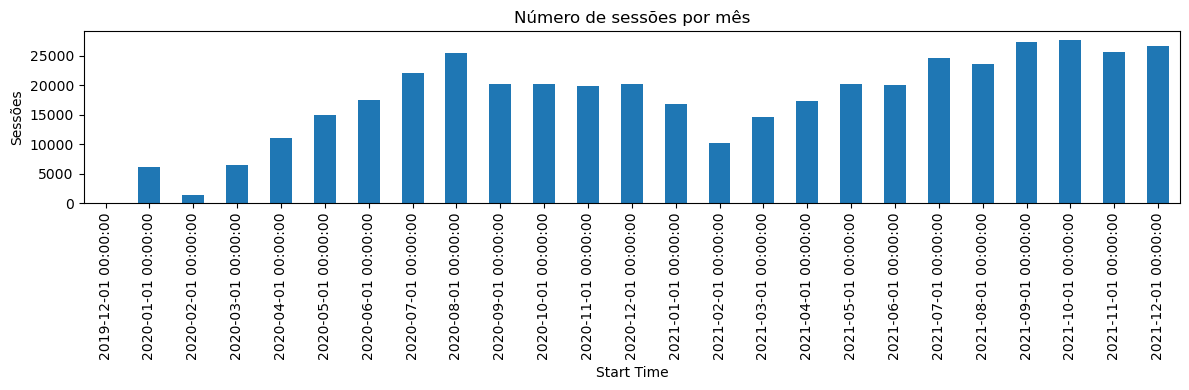

Start Time
2019-12-01       17
2020-01-01     6217
2020-02-01     1391
2020-03-01     6392
2020-04-01    11136
2020-05-01    15033
2020-06-01    17513
2020-07-01    22032
2020-08-01    25562
2020-09-01    20231
2020-10-01    20252
2020-11-01    19925
2020-12-01    20187
2021-01-01    16915
2021-02-01    10283
2021-03-01    14599
2021-04-01    17307
2021-05-01    20209
2021-06-01    20026
2021-07-01    24703
2021-08-01    23692
2021-09-01    27374
2021-10-01    27794
2021-11-01    25669
2021-12-01    26618
Freq: MS, dtype: int64

In [4]:
# Nº de sessões por mês -> ver se há meses incompletos ou anómalos
sessoes_mes = df.set_index('Start Time').resample('MS').size()

sessoes_mes.plot(kind='bar', figsize=(12, 4), color='tab:blue')
plt.title('Número de sessões por mês')
plt.ylabel('Sessões')
plt.tight_layout()
plt.show()

sessoes_mes

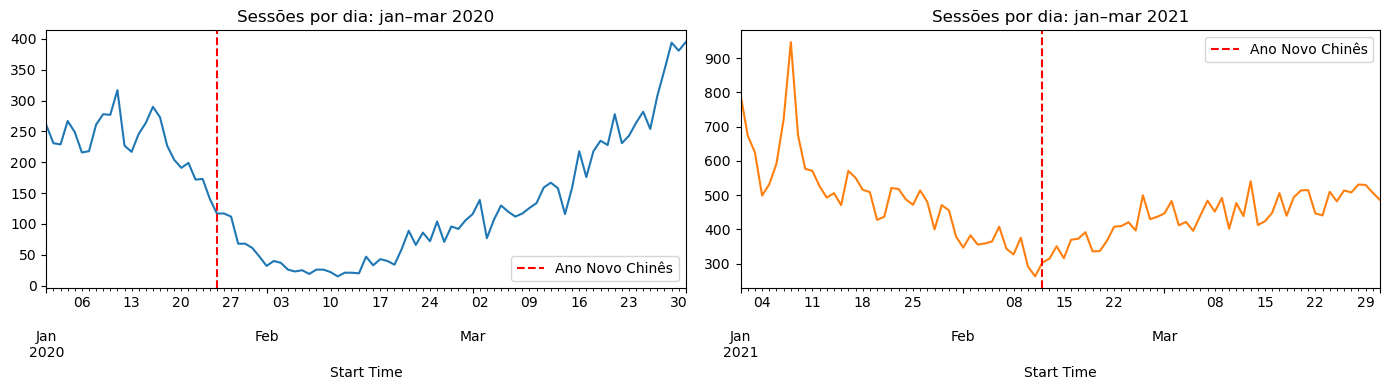

Start Time
2020-01    200.5
2020-02     48.0
2020-03    206.2
2020-04    371.2
2020-05    484.9
2020-06    583.8
2020-07    710.7
2020-08    824.6
2020-09    674.4
2020-10    653.3
2020-11    664.2
2020-12    651.2
2021-01    545.6
2021-02    367.2
2021-03    470.9
2021-04    576.9
2021-05    651.9
2021-06    667.5
2021-07    796.9
2021-08    764.3
2021-09    912.5
2021-10    896.6
2021-11    855.6
2021-12    858.6
dtype: float64

In [5]:
# Validar H2: sessões por DIA à volta do Ano Novo Chinês
# Ano Novo Chinês: 25/01/2020 e 12/02/2021
sessoes_dia = df.set_index('Start Time').resample('D').size()

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=False)

sessoes_dia['2020-01-01':'2020-03-31'].plot(ax=axes[0], color='tab:blue')
axes[0].axvline(pd.Timestamp('2020-01-25'), color='red', linestyle='--', label='Ano Novo Chinês')
axes[0].set_title('Sessões por dia: jan–mar 2020')
axes[0].legend()

sessoes_dia['2021-01-01':'2021-03-31'].plot(ax=axes[1], color='tab:orange')
axes[1].axvline(pd.Timestamp('2021-02-12'), color='red', linestyle='--', label='Ano Novo Chinês')
axes[1].set_title('Sessões por dia: jan–mar 2021')
axes[1].legend()

plt.tight_layout()
plt.show()

# Média diária por mês (corrige o efeito de fevereiro ter menos dias)
media_diaria = sessoes_dia['2020-01-01':].resample('MS').mean().round(1)
media_diaria.index = media_diaria.index.strftime('%Y-%m')
media_diaria

**Hipóteses e validação:**

- **H1 — Dezembro de 2019 é um mês incompleto: Confirmada.**
  A primeira sessão ocorre a 31/12/2019 às 21:27 (apenas 17 sessões). É um problema de **cobertura** e não procura real.
  **Decisão:** a série começa a **01/01/2020**.

- **H2 — As quebras de fevereiro são variações legítimas: Confirmada, com nuances.**
  - **2020:** quebra longa (de meados de janeiro ao fim de março), com mínimo de cerca de 20 sessões/dia. Compatível com o Ano Novo Chinês (25/01) e as restrições da COVID-19. É procura real, mas **atípica**.
  - **2021:** quebra moderada e concentrada à volta do Ano Novo Chinês (12/02). A média diária de fevereiro (367) é inferior à de janeiro (546), o que confirma que o efeito não se deve apenas a fevereiro ter menos dias.

  **Decisão:** não remover estes períodos (não são erros), mas **assinalar jan–mar 2020 como período atípico**, a considerar na escolha do período de treino (secção 2.6).

**Outras observações:**
- A procura tem uma **tendência crescente forte**: a média diária passa de ~200 (jan/2020) para ~860 (dez/2021).
- Não foram encontradas datas inválidas, sessões com fim antes do início nem linhas duplicadas.
- Cerca de 12% das transações têm 0 kWh (carregamentos interrompidos por falhas). Foram mantidas, porque são transações registadas e não erros de dados.

### 1.3 Construção das séries horárias

**Conceito: frequência e granularidade**
- **Frequência:** de quanto em quanto tempo temos um valor → **horária**
- **Granularidade:** a que nível agregamos → **rede** (total) e **distrito** (3 séries)

**Como construir:**
1. Arredondar o `Start Time` para baixo, à hora (`floor('h')`), porque o alvo são sessões que **começam** em cada hora
2. Contar as sessões por hora
3. Criar um índice com **todas** as horas do período. As horas sem nenhuma sessão não aparecem na contagem, por isso temos de as acrescentar com valor **0**

**Atenção:** uma hora sem sessões pode ser **procura zero real** (madrugada) ou **falha de registo**. Vamos analisar isso a seguir.

**Período:** de 01/01/2020 00:00 a 31/12/2021 23:00 (decisão da H1).

In [6]:
df['hora'] = df['Start Time'].dt.floor('h')

# Índice completo: todas as horas entre o início e o fim do período
idx = pd.date_range('2020-01-01 00:00', '2021-12-31 23:00', freq='h')

# Série da REDE
rede = df.groupby('hora').size().reindex(idx, fill_value=0)
rede.name = 'Rede'

# Séries por DISTRITO (uma coluna por distrito)
distritos = (df.groupby(['hora', 'District Name']).size()
               .unstack(fill_value=0)
               .reindex(idx, fill_value=0))

series = pd.concat([rede, distritos], axis=1)
series.index.name = 'hora'

print('Nº de horas:', len(series))
print('Confirmação (soma dos distritos = rede):',
      (series[distritos.columns].sum(axis=1) == series['Rede']).all())
series.head()

Nº de horas: 17544
Confirmação (soma dos distritos = rede): True


,Rede,Nanhu,Tongxiang,Xiuzhou
hora,,,,
2020-01-01 00:00:00,16,0,11,5
2020-01-01 01:00:00,3,2,1,0
2020-01-01 02:00:00,1,0,1,0
2020-01-01 03:00:00,5,0,4,1
2020-01-01 04:00:00,4,0,2,2


In [7]:
# Total de sessões na série (as 17 sessões de dez/2019 ficaram de fora)
print('Total de sessões nas séries:', series['Rede'].sum(), '\n')

# Horas com ZERO sessões em cada série
zeros = (series == 0).sum()
print('Horas com 0 sessões:')
pd.DataFrame({'n_horas': zeros, '% do total': (zeros / len(series) * 100).round(2)})

Total de sessões nas séries: 441060 

Horas com 0 sessões:


,n_horas,% do total
Rede,480,2.74
Nanhu,3582,20.42
Tongxiang,1012,5.77
Xiuzhou,1741,9.92


In [8]:
# Sequências de zeros consecutivos na REDE
# Zeros isolados de madrugada -> normal. Muitas horas seguidas a zero -> suspeito.
z = series['Rede'] == 0
grupo = (z != z.shift()).cumsum()

blocos = (series.loc[z, 'Rede']
          .groupby(grupo[z])
          .agg(inicio=lambda s: s.index.min(), n_horas='size')
          .sort_values('n_horas', ascending=False))

# Em que meses e a que horas do dia aparecem os zeros da rede?
zeros_rede = series.index[z]
print('Zeros da rede por mês:')
print(zeros_rede.to_period('M').value_counts().sort_index().to_string(), '\n')
print('Zeros da rede por hora do dia:')
print(zeros_rede.hour.value_counts().sort_index().to_dict(), '\n')

print('Os 10 blocos de zeros mais longos:')
blocos.head(10)

Zeros da rede por mês:
hora
2020-01     60
2020-02    277
2020-03     89
2020-04     11
2020-05      3
2020-10      1
2020-11      1
2020-12      3
2021-01      5
2021-02     13
2021-03      7
2021-04      2
2021-05      1
2021-06      4
2021-07      1
2021-08      1
2021-12      1
Freq: M 

Zeros da rede por hora do dia:
{0: 22, 1: 34, 2: 47, 3: 55, 4: 65, 5: 66, 6: 52, 7: 34, 8: 15, 9: 15, 10: 9, 11: 6, 12: 5, 13: 3, 14: 3, 15: 2, 16: 3, 17: 4, 18: 8, 19: 7, 20: 6, 21: 3, 22: 6, 23: 10} 

Os 10 blocos de zeros mais longos:


,inicio,n_horas
Rede,,
192,2020-02-13 23:00:00,12
198,2020-02-15 00:00:00,10
164,2020-02-09 22:00:00,10
172,2020-02-11 01:00:00,10
158,2020-02-09 01:00:00,9
102,2020-02-04 02:00:00,9
206,2020-02-16 23:00:00,8
230,2020-02-20 00:00:00,8
202,2020-02-16 00:00:00,8


In [9]:
# Sessões por mês em cada local de Nanhu (o distrito com mais horas a zero)
nanhu = df[df['District Name'] == 'Nanhu']
por_local = (nanhu.groupby([nanhu['Start Time'].dt.to_period('M'), 'Location Information'])
                  .size().unstack(fill_value=0))
por_local.loc['2021-06':]

Location Information,Financial Industrial Park,Technology Park,Tourist Attraction
Start Time,,,
2021-06,431,1340,596
2021-07,423,1567,870
2021-08,539,1415,906
2021-09,743,1251,2580
2021-10,1111,0,2862
2021-11,1271,0,2888
2021-12,1196,0,1563


In [10]:
# Zeros da rede FORA do período atípico (a partir de abril de 2020)
zeros_normais = zeros_rede[zeros_rede >= '2020-04-01']

print('Nº de zeros a partir de abr/2020:', len(zeros_normais))
print('Por hora do dia:', zeros_normais.hour.value_counts().sort_index().to_dict())

Nº de zeros a partir de abr/2020: 54
Por hora do dia: {2: 7, 3: 6, 4: 12, 5: 20, 6: 7, 7: 2}


**Hipóteses e validação:**

- **H3 - Séries com menor volume têm mais horas a zero: Confirmada.**
  Rede: 2,74% | Tongxiang: 5,77% | Xiuzhou: 9,92% | Nanhu: 20,42%.
  A ordem coincide com o volume de sessões de cada distrito. Em **Nanhu**, 1 em cada 5 horas não tem sessões, o que torna esta série mais **irregular** e, à partida, mais difícil de prever.

- **H4 - Os zeros da rede são procura real e não falhas de registo: Confirmada.**
  - 426 dos 480 zeros (~89%) ocorrem em **jan–mar 2020** (período atípico, ver H2);
  - fora desse período existem apenas 54 zeros, **todos entre as 2h e as 7h** (madrugada);
  - o bloco mais longo de zeros tem **12 horas** (fev/2020); **não existe nenhum dia inteiro sem sessões**.

**Decisão:** os zeros são mantidos como **procura zero real** (sem imputação). Ao nível da rede não há intervalos em falta. Ao nível dos locais há interrupções: o Technology Park (Nanhu) não tem sessões a partir de 29/09/2021, e o Tourist Attraction (Nanhu) não tem sessões entre 14 e 27/12/2021. Estes zeros não são falta de procura, mas sim postos sem atividade. Os valores foram mantidos, porque não é possível saber a procura real nesses dias, mas este período deve ser tido em conta ao avaliar as previsões de Nanhu.

## 2. Análise exploratória

### 2.1 Evolução e tendência

**Conceito: componentes de uma série temporal**

| Componente | O que é |
|---|---|
| **Nível** | valor médio da série |
| **Tendência** | aumento ou diminuição de longo prazo |
| **Sazonalidade** | padrão que se repete em intervalos fixos (ex.: todos os dias, todas as semanas) |
| **Ciclo** | flutuações longas sem duração fixa |
| **Ruído** | variação irregular e imprevisível |

Com dados **horários**, a série é muito "ruidosa" e é difícil ver a tendência.
Por isso, nesta secção agregamos por **dia** e usamos uma **média móvel de 30 dias**, que suaviza as oscilações de curto prazo e deixa ver a tendência.

**Conceito: média móvel**
A média móvel de 30 dias substitui cada valor pela média dos 30 dias à sua volta. Os padrões curtos (diário, semanal) desaparecem e fica a evolução de longo prazo.

In [11]:
# Divisão temporal (justificada na secção 4). A EDA usa só o período de treino.
TRAIN_END = '2021-06-30'
VALIDATION_START, VALIDATION_END = '2021-07-01', '2021-09-30'
TEST_START, TEST_END = '2021-10-01', '2021-12-31'

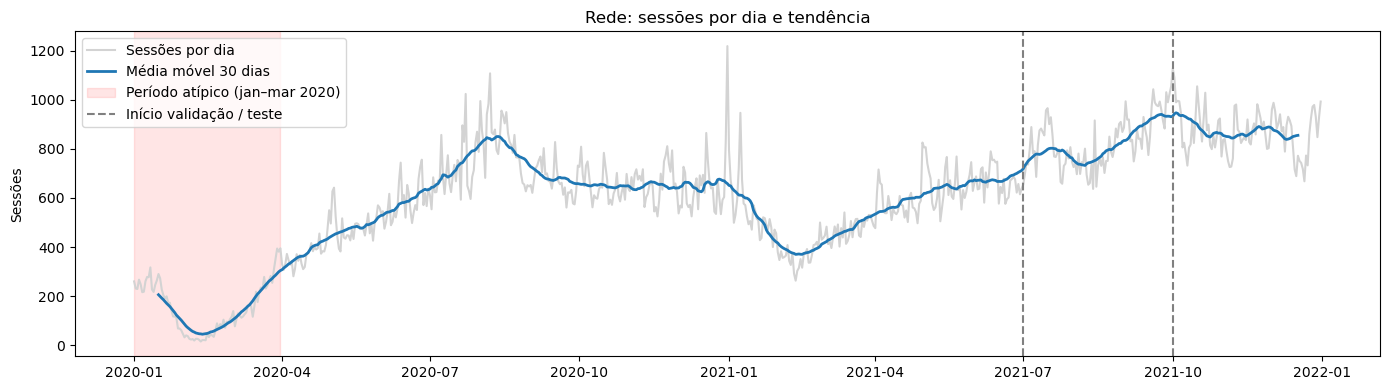

In [12]:
# Série diária (soma das 24 horas de cada dia)
diario = series.resample('D').sum()

# Média móvel de 30 dias (centrada)
mm30 = diario['Rede'].rolling(30, center=True).mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(diario.index, diario['Rede'], color='lightgray', label='Sessões por dia')
ax.plot(mm30.index, mm30, color='tab:blue', linewidth=2, label='Média móvel 30 dias')
ax.axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2020-03-31'),
           color='red', alpha=0.1, label='Período atípico (jan–mar 2020)')
ax.axvline(pd.Timestamp(VALIDATION_START), color='gray', linestyle='--', label='Início validação / teste')
ax.axvline(pd.Timestamp(TEST_START), color='gray', linestyle='--')
ax.set_title('Rede: sessões por dia e tendência')
ax.set_ylabel('Sessões')
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
# Média diária por trimestre -> resumo numérico da tendência
media_trimestral = diario['Rede'].resample('QS').mean().round(1)
media_trimestral.index = media_trimestral.index.to_period('Q').astype(str)
print('Média de sessões por dia, por trimestre:')
print(media_trimestral.to_string(), '\n')

# Os 5 dias com mais sessões (possíveis picos atípicos)
print('Os 5 dias com mais sessões:')
print(diario['Rede'].nlargest(5).to_string())

Média de sessões por dia, por trimestre:
hora
2020Q1    153.8
2020Q2    480.0
2020Q3    737.2
2020Q4    656.1
2021Q1    464.4
2021Q2    632.3
2021Q3    823.6
2021Q4    870.4 

Os 5 dias com mais sessões:
hora
2020-12-31    1219
2021-10-01    1128
2020-08-07    1108
2021-10-02    1091
2021-09-30    1055


**Hipóteses e validação:**

- **H5 - A procura média aumenta de trimestre para trimestre: Rejeitada tal como formulada, mas existe tendência crescente.**
  A média diária desce do 3.º para o 4.º trimestre de 2020 (737 → 656) e de novo no 1.º trimestre de 2021 (464).
  No entanto, comparando **trimestres homólogos**, a procura cresce sempre:

  | Trimestre | 2020 | 2021 |
  |---|---|---|
  | T1 | 153,8 | 464,4 |
  | T2 | 480,0 | 632,3 |
  | T3 | 737,2 | 823,6 |
  | T4 | 656,1 | 870,4 |

  **Conclusão:** existe uma **tendência crescente de longo prazo**, sobreposta a variações ao longo do ano. Por isso a série **não é estacionária** (a média não é constante).

- **H6 - Existe um padrão ao longo do ano: Sugerida, mas não confirmada.**
  Nos dois anos, a procura sobe até ao verão/outono e cai no inverno (jan–fev, Ano Novo Chinês). Com apenas 2 ciclos, e com 2020 afetado pela COVID-19, não é possível confirmar uma sazonalidade anual.

- **H7 - Os dias com mais sessões são picos associados a datas especiais: Confirmada.**
  - 31/12/2020 (1219 sessões): véspera de Ano Novo;
  - 30/09 a 02/10/2021: início do feriado do Dia Nacional da China (Golden Week);
  - 07/08/2020: sem explicação evidente no calendário.

  São procura real e não erros. **Implicação:** variáveis de calendário (feriados, vésperas de feriado) são candidatas a preditores (secção 3.3).

  Nota: este gráfico mostra o período completo apenas para descrever os dados. As linhas tracejadas marcam o início da validação e do teste. As análises que servem para tomar decisões (secções 2.2 a 2.5) usam apenas o período de treino, para não usar informação do teste.

### 2.2 Sazonalidade diária e semanal

**Conceito: sazonalidade e período sazonal *m***
A sazonalidade é um padrão que se repete em intervalos fixos. O **período sazonal *m*** é o número de observações de um ciclo completo:

| Padrão | Ciclo | *m* (em horas) |
|---|---|---|
| Diário | 1 dia | **24** |
| Semanal | 1 semana | **168** (7 × 24) |

No exemplo da aula (*Air Passengers*, dados mensais), *m* = 12. No nosso caso, com dados **horários**, podem existir **dois padrões ao mesmo tempo** (diário e semanal).

O *m* é uma decisão importante, porque vai ser usado:
- no **seasonal naïve** (prever "o mesmo valor de há *m* horas");
- no **MASE** (métrica de avaliação);
- na **decomposição STL** (secção 2.3).

**Como vamos analisar: perfis médios**
- **Perfil diário:** média de sessões para cada hora do dia (0h a 23h);
- **Perfil semanal:** média de sessões para cada dia da semana;
- **Perfil hora × dia da semana:** o perfil diário separado por dia da semana, para ver se a "forma" do dia muda (ex.: fim de semana vs. dias úteis).

**Decisão:** usamos os dados **a partir de 01/04/2020 e até ao fim do período de treino (30/06/2021)**, para o período atípico (jan–mar 2020) não distorcer as médias.

**Medida simples da intensidade de cada padrão:**
amplitude relativa = (máximo − mínimo) / média do perfil.
Quanto maior, mais forte é o padrão.

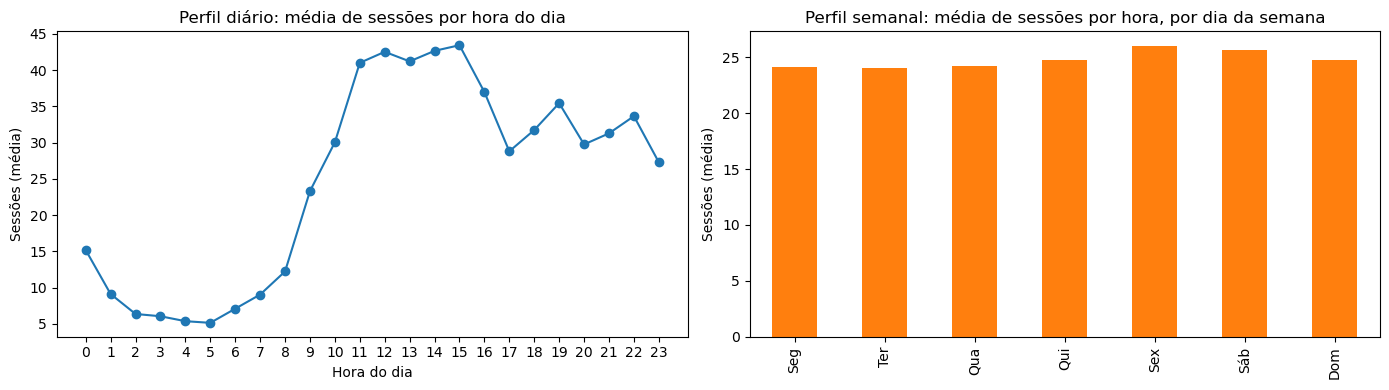

Amplitude relativa do padrão diário:  1.55
Amplitude relativa do padrão semanal: 0.08


In [14]:
# Dados a partir de abril de 2020 (sem o período atípico)
s = series.loc['2020-04-01':TRAIN_END, ['Rede']].copy()
s['hora_dia'] = s.index.hour
s['dia_semana'] = s.index.dayofweek          # 0 = segunda, 6 = domingo
nomes_dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']

# Perfil diário e perfil semanal (média de sessões por hora)
perfil_hora = s.groupby('hora_dia')['Rede'].mean()
perfil_dia = s.groupby('dia_semana')['Rede'].mean()
perfil_dia.index = nomes_dias

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

perfil_hora.plot(ax=axes[0], marker='o', color='tab:blue')
axes[0].set_title('Perfil diário: média de sessões por hora do dia')
axes[0].set_xlabel('Hora do dia')
axes[0].set_ylabel('Sessões (média)')
axes[0].set_xticks(range(0, 24))

perfil_dia.plot(kind='bar', ax=axes[1], color='tab:orange')
axes[1].set_title('Perfil semanal: média de sessões por hora, por dia da semana')
axes[1].set_ylabel('Sessões (média)')

plt.tight_layout()
plt.show()

# Amplitude relativa de cada padrão
def amplitude(perfil):
    return (perfil.max() - perfil.min()) / perfil.mean()

print(f'Amplitude relativa do padrão diário:  {amplitude(perfil_hora):.2f}')
print(f'Amplitude relativa do padrão semanal: {amplitude(perfil_dia):.2f}')

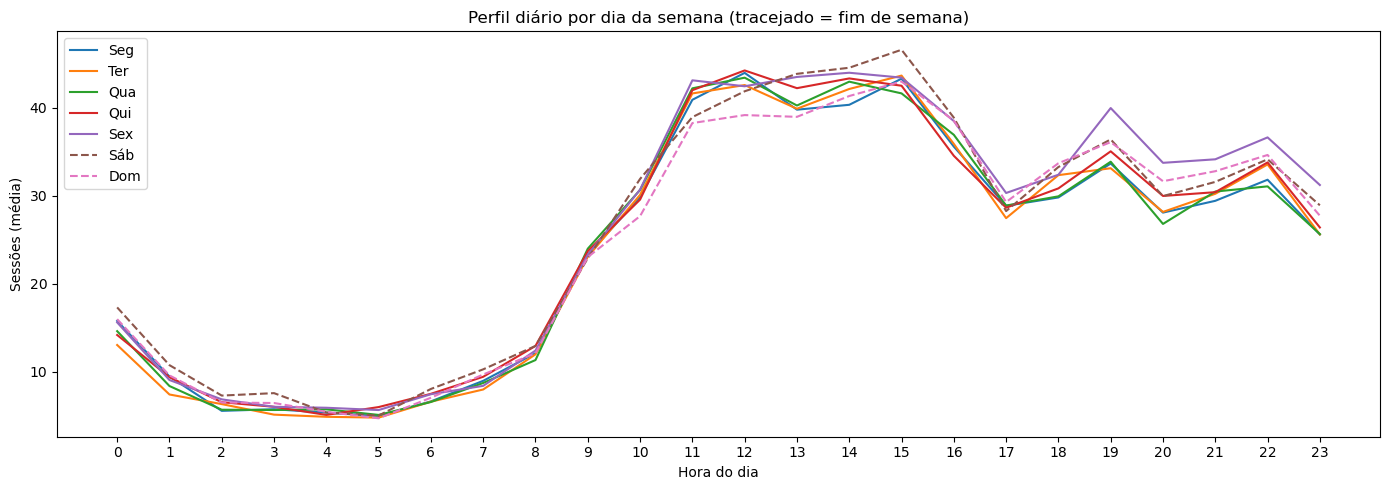

In [15]:
# Perfil diário separado por dia da semana -> a "forma" do dia muda ao fim de semana?
tabela = s.pivot_table(index='hora_dia', columns='dia_semana', values='Rede', aggfunc='mean')
tabela.columns = nomes_dias

fig, ax = plt.subplots(figsize=(14, 5))
for dia in nomes_dias:
    estilo = '--' if dia in ['Sáb', 'Dom'] else '-'
    ax.plot(tabela.index, tabela[dia], linestyle=estilo, label=dia)

ax.set_title('Perfil diário por dia da semana (tracejado = fim de semana)')
ax.set_xlabel('Hora do dia')
ax.set_ylabel('Sessões (média)')
ax.set_xticks(range(0, 24))
ax.legend()
plt.tight_layout()
plt.show()

**Hipóteses e validação:**

- **H8 - Existe uma sazonalidade diária forte (*m* = 24): Confirmada.**
  Amplitude relativa de **1,55**. O perfil diário apresenta:
  - mínimo entre as 4h e as 5h (~5 sessões/hora);
  - subida rápida entre as 8h e as 11h;
  - patamar máximo entre as 11h e as 15h (~41–43 sessões/hora, cerca de 8 vezes o mínimo);
  - quebra às 17h (~29) e um segundo pico às 19h (~35);
  - descida a partir das 23h.

- **H9 - O fim de semana tem um nível ou uma forma diferente dos dias úteis: Rejeitada.**
  Amplitude relativa do padrão semanal de apenas **0,08** (cerca de 20 vezes inferior à diária).
  Os perfis diários dos 7 dias estão praticamente sobrepostos. Existem apenas diferenças pequenas e localizadas:
  - domingo com menos procura entre as 11h e as 13h;
  - sábado com ligeiramente mais procura à tarde;
  - sexta-feira com mais procura à noite (19h–23h).

**Conclusão:** a sazonalidade **diária (*m* = 24) é dominante**. A sazonalidade semanal (*m* = 168) é fraca, mas não nula.

**Implicação para a previsão:** não se deve descartar *m* = 168 apenas com base nos perfis médios. A escolha final do *m* vai ser confirmada com a ACF (secção 2.4) e comparando os baselines seasonal naïve com *m* = 24 e *m* = 168 (secção 4.3).

### 2.3 Decomposição STL

**Conceito: decomposição**
A decomposição separa a série nas suas componentes:

- **Aditiva:** yₜ = Tendência + Sazonalidade + Resíduo → a amplitude sazonal é **constante**
- **Multiplicativa:** yₜ = Tendência × Sazonalidade × Resíduo → a amplitude sazonal **cresce com o nível** da série

**Conceito: STL**
O STL (*Seasonal and Trend decomposition using Loess*) é robusto a outliers e aceita qualquer período. É uma decomposição **aditiva**. Para uma série multiplicativa, aplica-se primeiro o **logaritmo**, que transforma a multiplicação em soma:

log(T × S × R) = log(T) + log(S) + log(R)

**Adaptações aos nossos dados:**
1. **log(1 + y) em vez de log(y):** a série tem horas com 0 sessões e log(0) não existe. A função `np.log1p` calcula log(1 + y) e resolve o problema.

**Conceito: força de uma componente (*seasonal strength*, notebook da aula)**

força = max(0, 1 − Var(resíduo) / Var(componente + resíduo))

Mede quanto da variação é explicada pela componente: **perto de 1 = forte**, **perto de 0 = fraca**.

**Dados usados:** a partir de 01/04/2020 e até ao fim do treino (30/06/2021), sem o período atípico (como na secção 2.2).

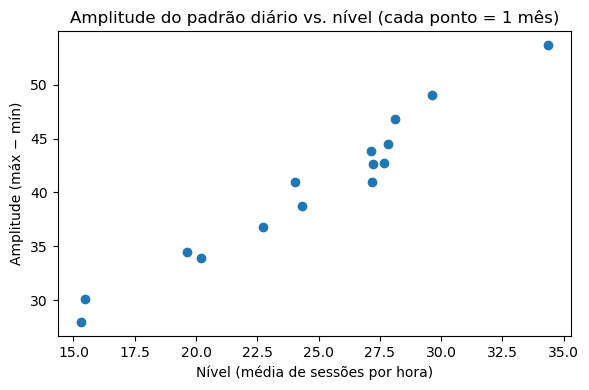

Correlação entre nível e amplitude: 0.98

Amplitude relativa (amplitude / nível) por mês:
count    15.00
mean      1.66
std       0.12
min       1.51
25%       1.58
50%       1.62
75%       1.69
max       1.95
dtype: float64


In [16]:
from statsmodels.tsa.seasonal import STL

# Teste: aditiva ou multiplicativa?
# Para cada mês, calculamos o nível (média) e a amplitude do perfil diário.
# Se a amplitude cresce com o nível -> multiplicativa.
y = series.loc['2020-04-01':TRAIN_END, 'Rede']

tmp = y.to_frame('sessoes')
tmp['mes'] = tmp.index.to_period('M')
tmp['hora_dia'] = tmp.index.hour

perfis_mes = tmp.groupby(['mes', 'hora_dia'])['sessoes'].mean().unstack()
nivel = perfis_mes.mean(axis=1)
amplitude_abs = perfis_mes.max(axis=1) - perfis_mes.min(axis=1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(nivel, amplitude_abs, color='tab:blue')
ax.set_title('Amplitude do padrão diário vs. nível (cada ponto = 1 mês)')
ax.set_xlabel('Nível (média de sessões por hora)')
ax.set_ylabel('Amplitude (máx − mín)')
plt.tight_layout()
plt.show()

print(f'Correlação entre nível e amplitude: {np.corrcoef(nivel, amplitude_abs)[0, 1]:.2f}')
print('\nAmplitude relativa (amplitude / nível) por mês:')
print((amplitude_abs / nivel).describe().round(2))

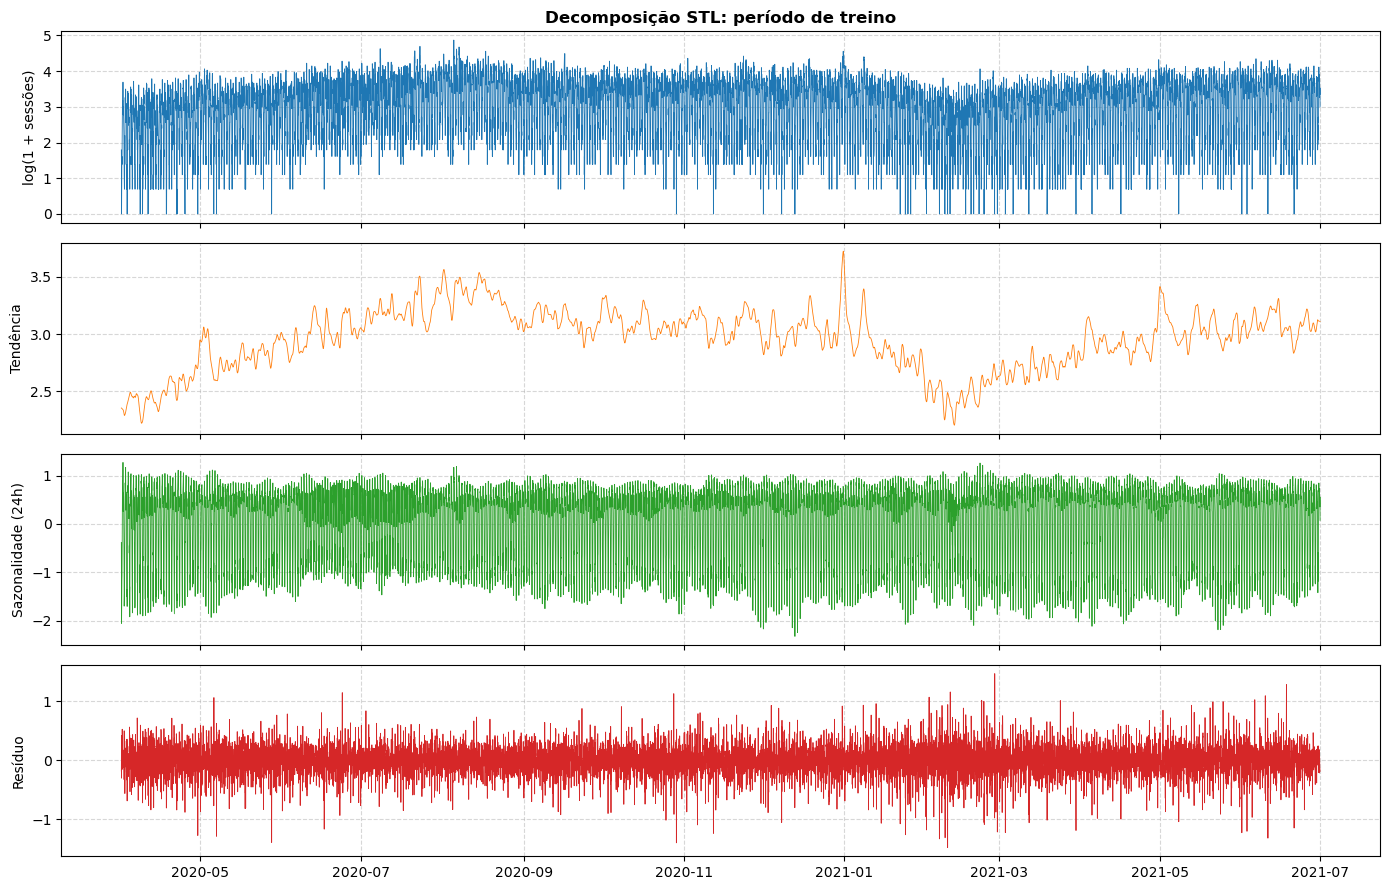

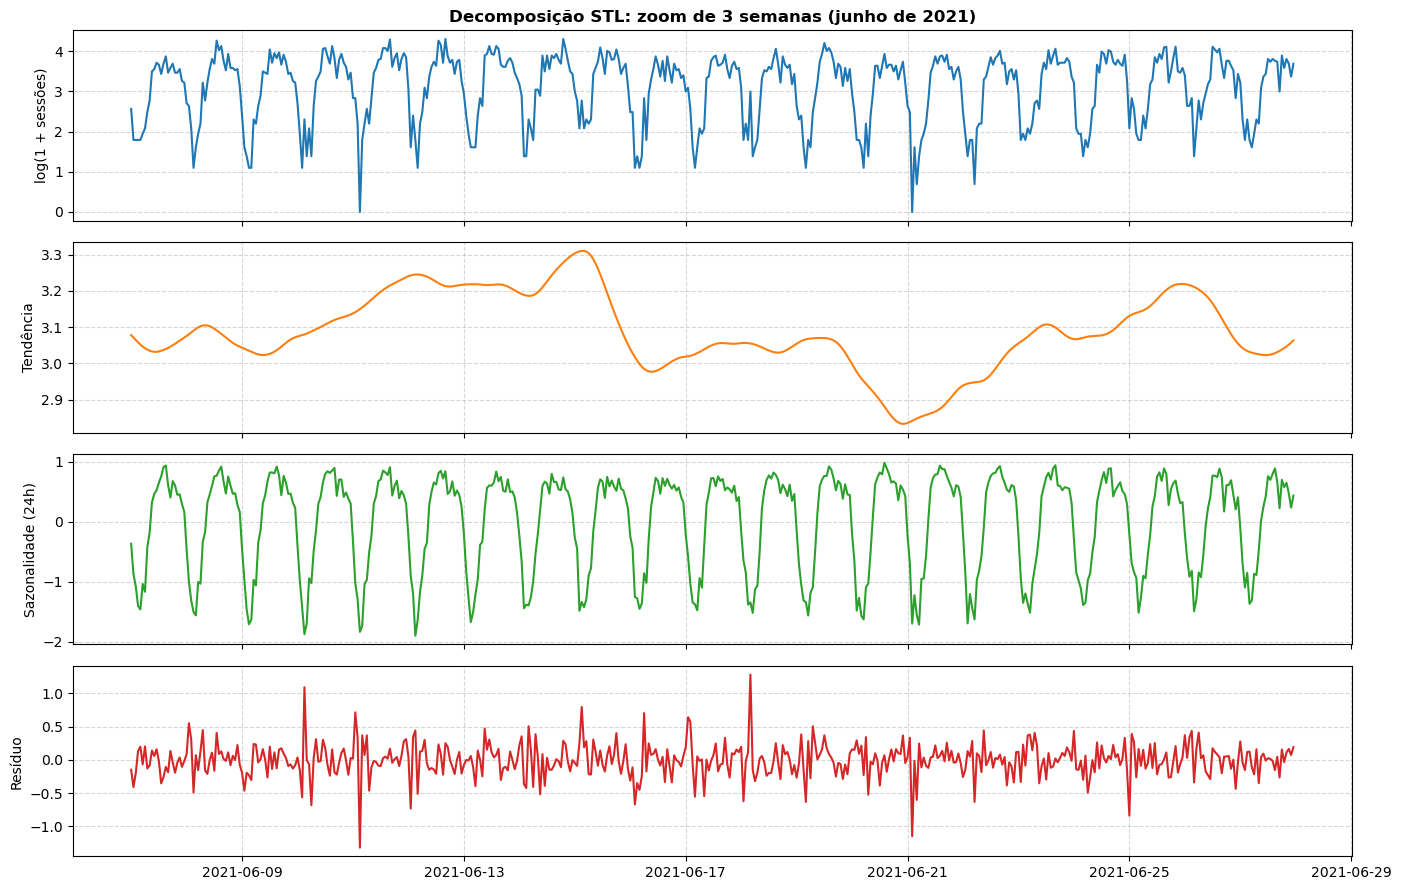

In [17]:
# Decomposição STL (como no notebook da aula): log(1 + y) e período de 24 horas
y_log = np.log1p(y)
decomp = STL(y_log, period=24).fit()

componentes = [(decomp.observed, 'log(1 + sessões)',   'tab:blue'),
               (decomp.trend,    'Tendência',          'tab:orange'),
               (decomp.seasonal, 'Sazonalidade (24h)', 'tab:green'),
               (decomp.resid,    'Resíduo',            'tab:red')]

# Gráfico 1: período de treino completo
fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
for ax, (comp, nome, cor) in zip(axes, componentes):
    ax.plot(comp, color=cor, linewidth=0.6)
    ax.set_ylabel(nome)
    ax.grid(True, linestyle='--', alpha=0.5)
axes[0].set_title('Decomposição STL: período de treino', fontweight='bold')
plt.tight_layout()
plt.show()

# Gráfico 2: zoom em 3 semanas (com milhares de horas não se veem os padrões)
janela = slice('2021-06-07', '2021-06-27')
fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
for ax, (comp, nome, cor) in zip(axes, componentes):
    ax.plot(comp.loc[janela], color=cor)
    ax.set_ylabel(nome)
    ax.grid(True, linestyle='--', alpha=0.5)
axes[0].set_title('Decomposição STL: zoom de 3 semanas (junho de 2021)', fontweight='bold')
plt.tight_layout()
plt.show()

In [18]:
# Força da sazonalidade (mesma fórmula do notebook da aula)
remainder = decomp.resid.dropna()
seasonal = decomp.seasonal.loc[remainder.index]

seasonal_strength = max(0, 1 - remainder.var() / (seasonal + remainder).var())
print(f'Força da sazonalidade (24h): {seasonal_strength:.3f}')

Força da sazonalidade (24h): 0.906


**Hipóteses e validação:**

- **H10 - A série é multiplicativa: Confirmada.**
  A amplitude do padrão diário cresce com o nível da série (correlação de **0,98** entre o nível e a amplitude mensais, no período de treino). A amplitude relativa mantém-se aproximadamente constante (média de **1,66**, desvio padrão de 0,12), o que corresponde à definição de sazonalidade multiplicativa (slide 15).
  Por isso, aplicou-se a transformação log(1 + y) antes da STL, como no notebook da aula (slide 16).

- **H11 - A sazonalidade diária (24h) é forte: Confirmada.**
  A força da sazonalidade é de **0,906**, muito perto de 1. A componente sazonal repete a mesma forma todos os dias, e a tendência reproduz a evolução observada na secção 2.1.

**Nota:** a STL decompõe uma única sazonalidade. Usou-se a dominante (24h), porque a semanal é fraca (secção 2.2). A sazonalidade semanal é verificada com a ACF na secção 2.4.

**Conclusões:**
- O **padrão diário é dominante**, o que confirma a secção 2.2.
- A série deve ser tratada como **multiplicativa**, e a transformação log(1 + y) é uma opção a considerar nos modelos das próximas tarefas.

### 2.4 Autocorrelação (ACF / PACF)

**Conceito: lag e autocorrelação**
Um **lag** é a distância temporal entre duas observações. Com dados horários:
- lag 1 → compara yₜ com a hora anterior (yₜ₋₁)
- lag 24 → compara yₜ com a mesma hora do dia anterior (yₜ₋₂₄)
- lag 168 → compara yₜ com a mesma hora da semana anterior (yₜ₋₁₆₈)

A **ACF** (função de autocorrelação) mede a correlação da série consigo própria em cada lag.

**Como ler a ACF:**
- **Picos em múltiplos de *m*** → sazonalidade com período *m* (no exemplo da aula, pico no lag 12)
- **Decaimento lento** → possível tendência / não estacionariedade
- Valores dentro da **banda sombreada (intervalo de confiança)** → não significativos

**Conceito: PACF**
A ACF inclui relações **diretas e indiretas** (yₜ ← yₜ₋₁ ← yₜ₋₂). A **PACF** mede apenas a relação **direta** entre yₜ e yₜ₋ₖ, depois de remover o efeito dos lags intermédios. Ajuda a perceber **que lags passados são realmente úteis** para prever.

**Como testar a sazonalidade semanal:**
Se existir um padrão semanal, o lag 168 deve ter uma autocorrelação **maior** que os lags vizinhos 144 e 192 (que correspondem a "6 dias" e "8 dias" atrás).

**Conceito: diferenciação sazonal**
Δ₂₄yₜ = yₜ − yₜ₋₂₄ remove ou reduz o padrão diário. Se depois disso ainda houver um pico no lag 168, existe informação semanal **para além** do padrão diário.

**Dados usados:** log(1 + y) de 01/04/2020 até ao fim do treino (30/06/2021), tal como na secção 2.3.

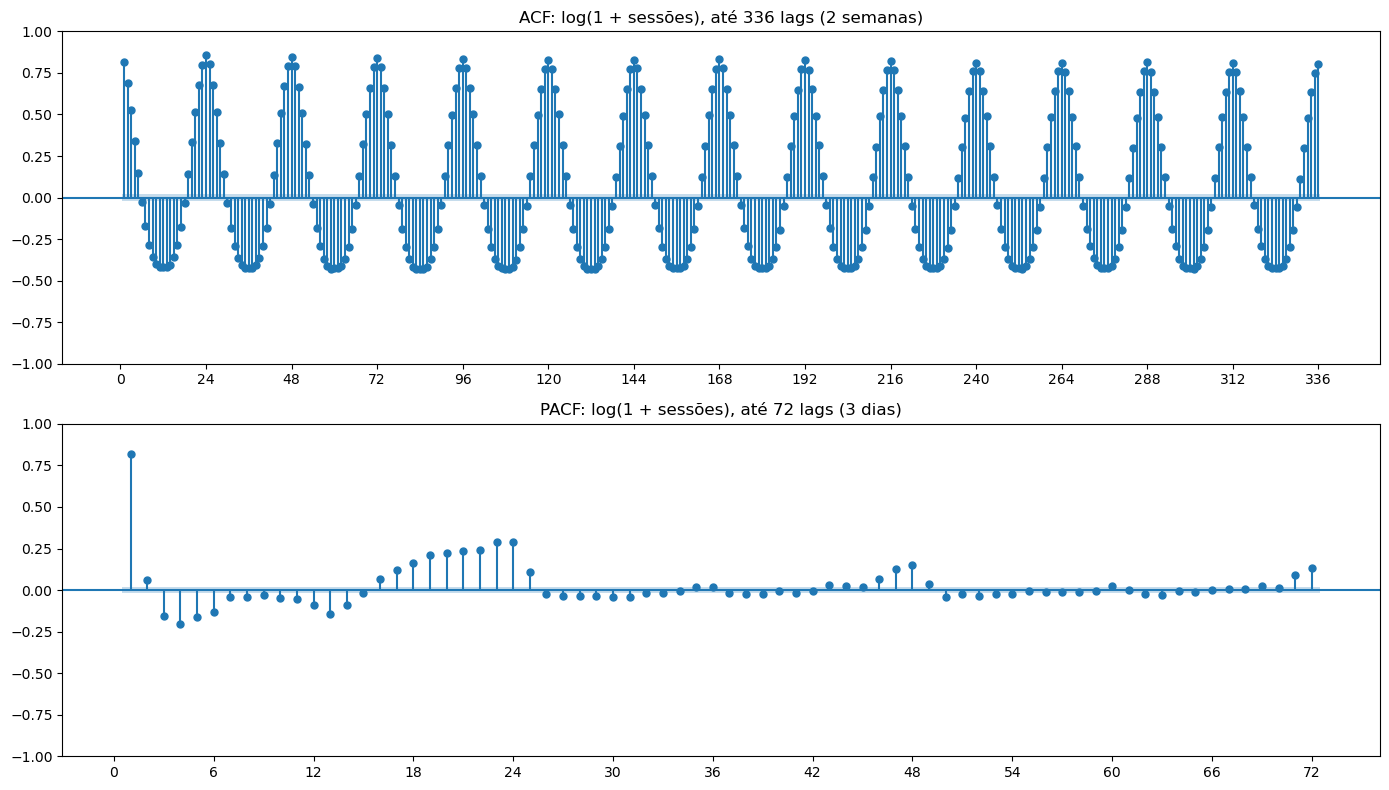

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf

# y_log já foi criado na secção 2.3: log(1 + sessões) a partir de abr/2020
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

plot_acf(y_log, lags=336, zero=False, bartlett_confint=False, ax=axes[0])
axes[0].set_title('ACF: log(1 + sessões), até 336 lags (2 semanas)')
axes[0].set_xticks(range(0, 337, 24))

plot_pacf(y_log, lags=72, zero=False, method='ywm', ax=axes[1])
axes[1].set_title('PACF: log(1 + sessões), até 72 lags (3 dias)')
axes[1].set_xticks(range(0, 73, 6))

plt.tight_layout()
plt.show()

In [20]:
# Valores da ACF em lags-chave
def tabela_acf(serie, lags):
    valores = acf(serie, nlags=max(lags))
    return pd.Series({lag: round(valores[lag], 3) for lag in lags}, name='ACF')

lags_chave = [1, 2, 12, 24, 48, 144, 167, 168, 169, 192, 336]
print('ACF da série log(1 + y):')
print(tabela_acf(y_log, lags_chave).to_string())

ACF da série log(1 + y):
1      0.817
2      0.687
12    -0.418
24     0.856
48     0.844
144    0.829
167    0.775
168    0.831
169    0.778
192    0.825
336    0.806


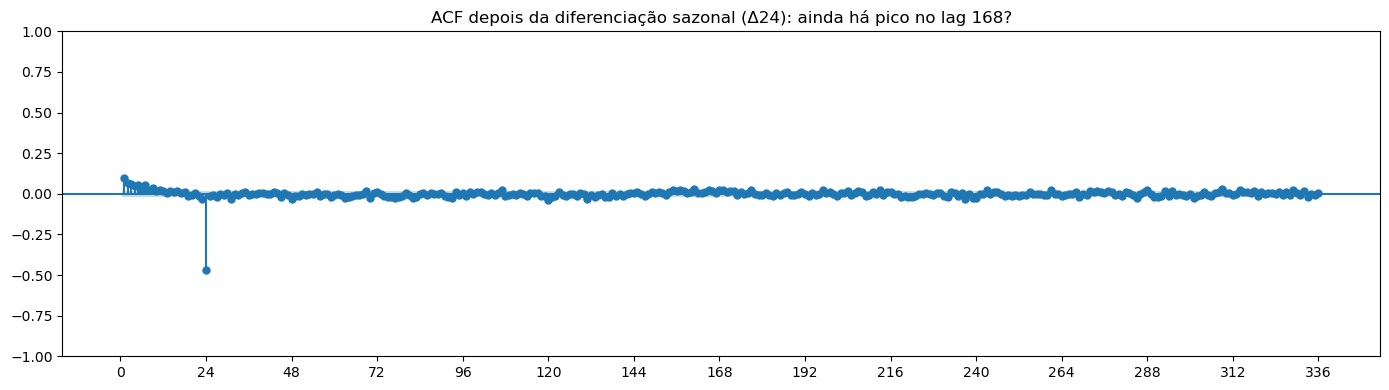

ACF da série diferenciada (Δ24):
1      0.096
24    -0.466
48    -0.031
144    0.003
168    0.024
192   -0.003
336    0.005


In [21]:
# ACF depois de remover o padrão diário (diferenciação sazonal com lag 24)
y_dif24 = y_log.diff(24).dropna()

fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(y_dif24, lags=336, zero=False, bartlett_confint=False, ax=ax)
ax.set_title('ACF depois da diferenciação sazonal (Δ24): ainda há pico no lag 168?')
ax.set_xticks(range(0, 337, 24))
plt.tight_layout()
plt.show()

print('ACF da série diferenciada (Δ24):')
print(tabela_acf(y_dif24, [1, 24, 48, 144, 168, 192, 336]).to_string())

**Hipóteses e validação:**

- **H12 - A ACF tem picos em todos os múltiplos de 24: Confirmada.**
  Os picos em 24, 48, 72, …, 336 têm valores entre ~0,81 e ~0,86, e os vales em 12, 36, 60, … (~−0,42) correspondem à oposição dia/noite.
  O **decaimento é muito lento** (0,856 no lag 24 → 0,806 no lag 336), o que é sinal de tendência / não estacionariedade (slide 21).

- **H13 - Existe uma sazonalidade semanal relevante (lag 168): Fraca.**

  | Lag | ACF (log) | ACF depois de Δ24 |
  |---|---|---|
  | 144 (6 dias) | 0,829 | 0,003 |
  | **168 (7 dias)** | **0,831** | **0,024** |
  | 192 (8 dias) | 0,825 | −0,003 |

  O lag 168 praticamente não se destaca dos vizinhos. Depois de remover o padrão diário (Δ24), a autocorrelação no lag 168 é de apenas 0,024, muito próxima de zero. A semana anterior acrescenta **muito pouca informação** para além do padrão diário.
  O valor de −0,47 no lag 24 depois da diferenciação é um efeito da própria diferenciação sazonal (tal como o lag 12 no exemplo *Air Passengers* da aula).

- **H14 - A série não é estacionária: Confirmada**
  A média não é constante: existe uma tendência crescente, a componente de tendência da STL varia entre ~2,2 e ~3,7 (escala log) e a ACF decai lentamente.

**PACF - lags com relação direta:**
- **Lag 1** (0,82): a hora anterior é o preditor direto mais forte;
- **Lags 23-24** (~0,29): a mesma hora do dia anterior;
- **Lags 48 e 72** (~0,15 e ~0,13): a mesma hora de 2 e 3 dias antes.

**Implicações para a formulação (secções 3 e 4):**
- ***m* = 24** é o período sazonal dominante, confirmado por três técnicas (perfis médios, STL e ACF).
- Numa previsão para as próximas 24 horas, o lag 1 não está disponível para a maioria dos horizontes. O **lag 24** está disponível para todos os horizontes (1 a 24h), o que o torna um preditor central e justifica o seasonal naïve com *m* = 24 como baseline principal.

### 2.5 Diferenças entre distritos

O enunciado pede previsões a **dois níveis de agregação**: a rede e cada um dos 3 distritos (Nanhu, Tongxiang e Xiuzhou).
As conclusões das secções anteriores foram tiradas para a **rede**. Agora verificamos se se aplicam também a cada distrito, ou se há diferenças que justifiquem um tratamento distinto.

**O que vamos comparar:**
1. **Volume e variabilidade:** quanto pesa cada distrito na rede e quão irregular é a sua série
2. **Tendência:** os distritos crescem todos ao mesmo ritmo?
3. **Forma do padrão diário:** a "forma" do dia é igual nos 3 distritos?
4. **Autocorrelação:** a sazonalidade de 24h é igualmente forte em todos?

**Conceito: coeficiente de variação (CV)**
CV = desvio padrão / média. Mede a variabilidade **relativa** e permite comparar séries com volumes diferentes. Quanto maior o CV, mais irregular é a série.

**Conceito: perfil normalizado**
Para comparar a **forma** do dia entre distritos com volumes muito diferentes, divide-se cada perfil pela sua média. Assim, o valor 1 corresponde à média do distrito: 1,5 significa "50% acima da média", 0,5 significa "50% abaixo".

**Dados usados:** período de treino, a partir de 01/04/2020 e até 30/06/2021 (exceto no gráfico da tendência e do peso na rede, que começam em 01/01/2020).

In [23]:
nomes_distritos = ['Nanhu', 'Tongxiang', 'Xiuzhou']
d = series.loc['2020-04-01':TRAIN_END]

# 1) Volume e variabilidade
resumo = pd.DataFrame({
    'Total sessões':  d.sum(),
    '% da rede':      (d.sum() / d['Rede'].sum() * 100).round(1),
    'Média por hora': d.mean().round(2),
    'Desvio padrão':  d.std().round(2),
    'CV':             (d.std() / d.mean()).round(2),
    '% horas a zero': ((d == 0).mean() * 100).round(1),
})
resumo

,Total sessões,% da rede,Média por hora,Desvio padrão,CV,% horas a zero
Rede,271210,100.0,24.78,16.75,0.68,0.5
Nanhu,47467,17.5,4.34,4.20,0.97,15.6
Tongxiang,139891,51.6,12.78,9.34,0.73,2.3
Xiuzhou,83852,30.9,7.66,6.27,0.82,7.3


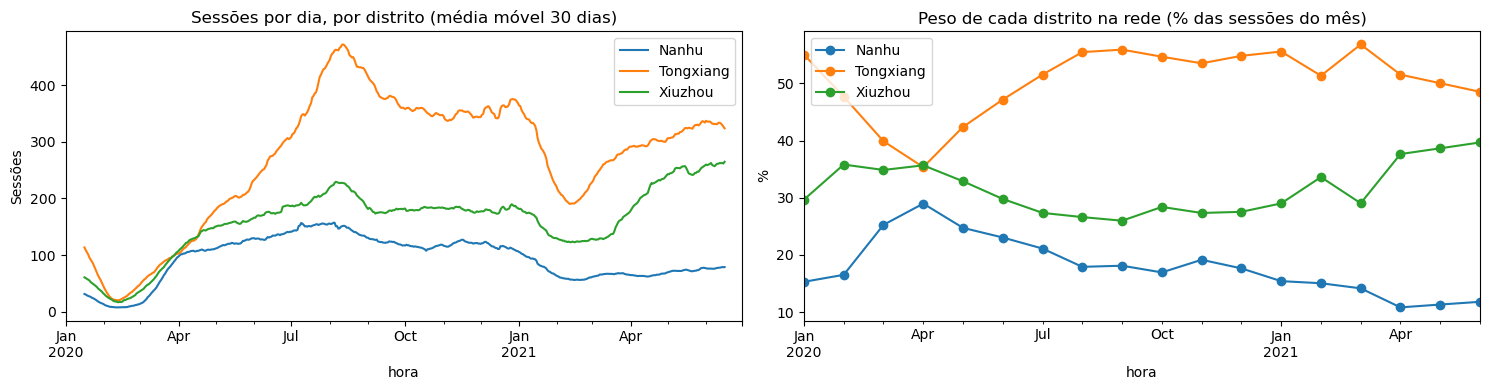

,Nanhu,Tongxiang,Xiuzhou
hora,,,
2020Q1,20.0,47.4,32.6
2020Q2,25.1,42.5,32.4
2020Q3,19.0,54.3,26.7
2020Q4,17.9,54.3,27.8
2021Q1,14.9,54.9,30.2
2021Q2,11.4,49.9,38.7


In [24]:
# 2) Tendência de cada distrito e evolução do peso na rede
diario_d = series.loc[:TRAIN_END, nomes_distritos].resample('D').sum()
mm30_d = diario_d.rolling(30, center=True).mean()

quota = series.loc[:TRAIN_END, nomes_distritos].resample('MS').sum()
quota = quota.div(quota.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

mm30_d.plot(ax=axes[0])
axes[0].set_title('Sessões por dia, por distrito (média móvel 30 dias)')
axes[0].set_ylabel('Sessões')

quota.plot(ax=axes[1], marker='o')
axes[1].set_title('Peso de cada distrito na rede (% das sessões do mês)')
axes[1].set_ylabel('%')

plt.tight_layout()
plt.show()

# Peso por trimestre (tabela resumo)
quota_trim = series.loc[:TRAIN_END, nomes_distritos].resample('QS').sum()
quota_trim = (quota_trim.div(quota_trim.sum(axis=1), axis=0) * 100).round(1)
quota_trim.index = quota_trim.index.to_period('Q').astype(str)
quota_trim

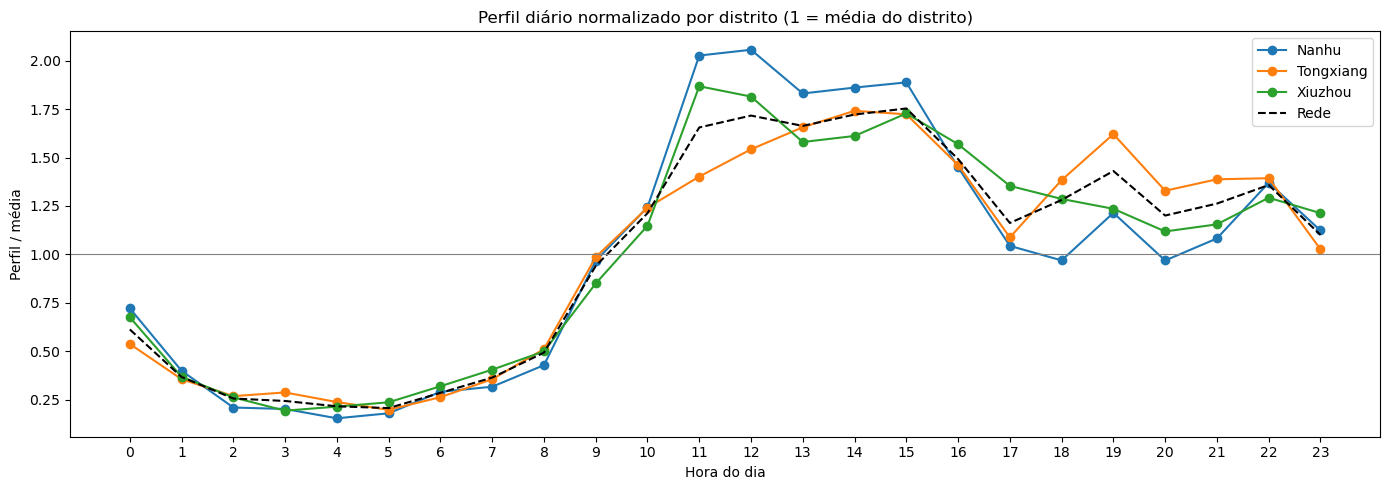

Correlação entre os perfis diários dos distritos:
           Nanhu  Tongxiang  Xiuzhou
Nanhu      1.000      0.924    0.974
Tongxiang  0.924      1.000    0.948
Xiuzhou    0.974      0.948    1.000


In [25]:
# 3) Forma do padrão diário: perfis normalizados (perfil / média)
perfis = d.groupby(d.index.hour)[nomes_distritos + ['Rede']].mean()
perfis_norm = perfis / perfis.mean()

fig, ax = plt.subplots(figsize=(14, 5))
for c in nomes_distritos:
    ax.plot(perfis_norm.index, perfis_norm[c], marker='o', label=c)
ax.plot(perfis_norm.index, perfis_norm['Rede'], color='black', linestyle='--', label='Rede')
ax.axhline(1, color='gray', linewidth=0.8)
ax.set_title('Perfil diário normalizado por distrito (1 = média do distrito)')
ax.set_xlabel('Hora do dia')
ax.set_ylabel('Perfil / média')
ax.set_xticks(range(0, 24))
ax.legend()
plt.tight_layout()
plt.show()

# Semelhança entre as formas: correlação entre os perfis normalizados
print('Correlação entre os perfis diários dos distritos:')
print(perfis_norm[nomes_distritos].corr().round(3))

In [26]:
# 4) Autocorrelação em lags-chave para cada série (escala log)
linhas = {}
for c in ['Rede'] + nomes_distritos:
    v = acf(np.log1p(d[c]), nlags=168)
    linhas[c] = {'lag 1': v[1], 'lag 24': v[24], 'lag 144': v[144], 'lag 168': v[168]}

print('ACF de log(1 + y) por série:')
pd.DataFrame(linhas).T.round(3)

ACF de log(1 + y) por série:


,lag 1,lag 24,lag 144,lag 168
Rede,0.817,0.856,0.829,0.831
Nanhu,0.614,0.651,0.633,0.640
Tongxiang,0.763,0.804,0.770,0.772
Xiuzhou,0.654,0.668,0.645,0.645


**Hipóteses e validação:**

- **H15 - Os distritos de menor volume são mais irregulares: Confirmada.**

  | Série | % da rede | CV | % horas a zero |
  |---|---|---|---|
  | Tongxiang | 51,6 | 0,73 | 2,3 |
  | Xiuzhou | 30,9 | 0,82 | 7,3 |
  | Nanhu | 17,5 | 0,97 | 15,6 |

  A ordem por volume coincide com a ordem por CV e por % de horas a zero. (A % de zeros de Nanhu é inferior à da secção 1.3 porque aqui o período atípico jan–mar 2020 está excluído.)

- **H16 - Os 3 distritos seguem a mesma tendência: Rejeitada.**
  O peso de cada distrito na rede varia ao longo do tempo:
  - **Nanhu** perde peso (25,1% no 2.º trimestre de 2020 → 11,4% no 2.º trimestre de 2021);
  - **Xiuzhou** ganha peso (~27% no 2.º semestre de 2020 → 38,7% no 2.º trimestre de 2021);
  - **Tongxiang** tem um pico no 2.º semestre de 2020 (54,3%) e desce para ~50% no 2.º trimestre de 2021.

  Cada distrito tem a sua própria tendência. **Implicação:** não é adequado prever a rede e repartir a previsão por percentagens fixas. Cada distrito deve ter a sua própria previsão, e os dados mais recentes são mais representativos do comportamento atual.

- **H17 - Os 3 distritos têm a mesma forma de padrão diário: Parcialmente confirmada.**
  A forma geral é semelhante (correlação entre perfis de 0,92 a 0,97): madrugada baixa, subida entre as 8h e as 11h e patamar durante o dia. ***m* = 24 é válido para todos.**
  Diferenças nos detalhes:
  - **Nanhu:** pico acentuado às 11–12h (~2 vezes a sua média), quebras às 17–18h e às 20h e pico às 22h;
  - **Tongxiang:** subida mais gradual de manhã e pico noturno mais forte às 19h;
  - **Xiuzhou:** perfil mais próximo do da rede.

- **H18 - A sazonalidade de 24h é dominante em todos os distritos: Confirmada.**

  | Série | lag 1 | lag 24 | lag 144 | lag 168 |
  |---|---|---|---|---|
  | Rede | 0,817 | 0,856 | 0,829 | 0,831 |
  | Tongxiang | 0,763 | 0,804 | 0,770 | 0,772 |
  | Xiuzhou | 0,654 | 0,668 | 0,645 | 0,645 |
  | Nanhu | 0,614 | 0,651 | 0,633 | 0,640 |

  Em todas as séries o lag 24 é o mais elevado, e o lag 168 é praticamente igual ao lag 144.
  A autocorrelação diminui com o volume: a série de **Nanhu é a mais ruidosa** e, à partida, a mais difícil de prever; a **rede é a mais previsível**, porque a agregação compensa parte do ruído dos distritos.

**Implicação para a avaliação:** as séries têm escalas muito diferentes (Nanhu ~4,3 sessões/hora; rede ~25), por isso o MAE e o RMSE não são comparáveis entre séries. O **MASE**, por ser relativo ao seasonal naïve de cada série, permite essa comparação.

## 3. Formulação operacional

### 3.1 Formulação do problema

**Conceito: origem e horizonte de previsão**
Uma previsão está sempre associada a uma **origem** *t* (o momento em que é feita) e a um **horizonte** *h* (quantos passos à frente).
Escreve-se ŷ<sub>t+h|t</sub>: previsão para o instante *t + h*, usando só a informação disponível em *t*.

**Emissão da previsão:** uma vez por dia, **no fim de cada dia** (desenho *daily multi-step*).
- Origem *t*: última hora observada do dia D (23:00).
- Horizontes *h* = 1, …, 24: as 24 horas do dia seguinte (h = 1 → 00:00 de D+1; h = 24 → 23:00 de D+1).
- Próxima origem: um dia depois.

Esta escolha cumpre o objetivo do projeto (24 previsões horárias em cada instância de previsão) e cada previsão cobre um dia completo, o que é útil para planear a operação do dia seguinte.

| Elemento | Pergunta | O nosso problema |
|---|---|---|
| Alvo *y<sub>t</sub>* | O que prevemos? | Nº de sessões de carregamento que começam em cada hora |
| Unidade de análise | Para que entidade? | 4 séries: Rede, Nanhu, Tongxiang e Xiuzhou (cada uma com a sua previsão, ver H16) |
| Frequência | Com que resolução temporal? | Horária |
| Origem *t* | Quando é feita a previsão? | No fim de cada dia (última hora observada: 23:00) |
| Horizonte *H* | Até onde prevemos? | Próximas 24 horas (h = 1, …, 24) |
| Janela de entrada *L* | Quanto histórico usamos? | Todo o histórico disponível a partir de 01/04/2020 (ver 2.6) |
| Período sazonal *m* | De quanto em quanto tempo se repete o padrão? | 24 horas (ver 2.3 e 2.4) |
| Preditores | O que é conhecido em *t*? | Sessões passadas e informação de calendário (ver 3.3) |
| Métricas | Como medimos o erro? | MAE, RMSE e MASE (ver 4.2) |
| Baseline | O que o modelo tem de superar? | *Seasonal naïve* (ver 4.3) |

### 3.2 Estratégia multi-step

**Conceito: previsão multi-step**
Prever vários passos futuros (*t*+1, *t*+2, …, *t*+*H*) e não apenas a observação seguinte. Há duas estratégias principais:

| Estratégia | Como funciona | Vantagens | Desvantagens |
|---|---|---|---|
| **Recursiva** | Um só modelo prevê *t*+1; a previsão é usada como entrada para prever *t*+2, e assim até *t*+*H* | Só um modelo (eficiente); horizonte flexível | **Acumulação de erros**: os erros dos primeiros passos são usados como se fossem valores reais |
| **Direta** | Um modelo por horizonte (*f*<sub>1</sub> para *t*+1, …, *f*<sub>H</sub> para *t*+*H*), todos com a mesma janela de valores reais | **Sem propagação de erros** | Custo computacional maior (*H* modelos); cada horizonte é previsto de forma independente |

**Estratégia escolhida: direta**, com 24 modelos por série (*h* = 1, …, 24).

Justificação:
- O horizonte é **fixo** (24 horas), por isso a flexibilidade da estratégia recursiva não é necessária.
- Com 24 passos, a estratégia recursiva acumularia erros: a última hora do dia seguinte seria prevista a partir de 23 previsões.
- O preditor mais forte é a mesma hora do dia anterior (**lag 24**, ver 2.4). Na estratégia direta, este valor é **sempre observado** na origem para qualquer *h* entre 1 e 24.
- O custo de treinar 24 modelos é aceitável, porque a previsão é emitida **apenas uma vez por dia**. Este custo será tido em conta na avaliação (requisitos computacionais).

### 3.3 Preditores e prevenção de leakage

**Conceito: data leakage**
Há *leakage* quando o modelo usa informação que **não estaria disponível no momento da previsão** (origem *t*). Os resultados parecem bons na avaliação, mas não se repetem na prática.

**Conceito: sliding window (janela deslizante)**
Os modelos de ML precisam de dados em formato tabular (preditores → alvo). A janela deslizante transforma a série em pares *entrada* (últimos *k* valores, *lookback*) → *saída* (valor a prever em *t* + *h*).

**Preditores selecionados** (para cada série e cada horizonte *h*)

| Tipo | Preditor | Disponível em *t*? | Justificação |
|---|---|---|---|
| Histórico | Sessões das **últimas 24 horas** (*y*<sub>t−23</sub>, …, *y*<sub>t</sub>; lookback *k* = 24) | Sim (valores observados) | Captura o padrão diário (*m* = 24). Com a origem às 23:00, a mesma hora do dia anterior (lag 24, o preditor mais forte, ver 2.4) está sempre dentro da janela, para qualquer *h* |
| Histórico agregado | **Média móvel das últimas 168 horas**, calculada com `.shift()` | Sim (só usa valores passados) | Dá o nível recente da série: tendência (H5) e mudanças de nível (interrupções em Nanhu) |
| Futuro conhecido | **Dia da semana** e **fim de semana** do dia previsto | Sim (o calendário é conhecido antecipadamente) | Captura a sazonalidade semanal, que é fraca (H12, H13) sem ser preciso um lookback de 336 horas |

A **hora do dia** não é usada como preditor: como a origem é sempre às 23:00, cada modelo *f*<sub>h</sub> prevê sempre a mesma hora (h = 1 → 00:00, …, h = 24 → 23:00), por isso a hora já está implícita no horizonte.

**Variáveis excluídas**

| Variável | Tipo | Motivo da exclusão |
|---|---|---|
| **Meteorologia** (temperatura, humidade, etc.) | Exógena com valor futuro **não disponível** | O tempo observado no dia seguinte não é conhecido na origem; o dataset não contém previsões meteorológicas; os registos só existem nas horas com sessões, por isso não há uma série meteorológica completa |
| Energia (kWh), duração, tarifas, etc. | Atributos de cada sessão | Só são conhecidos quando a sessão termina; o alvo é apenas o número de sessões que começam |

**Como evitamos o leakage**
- Todos os preditores são calculados apenas com valores observados até à origem *t* (as estatísticas móveis usam `.shift()`).
- Cada série (rede e distritos) usa apenas a sua própria história.
- A avaliação respeita a ordem cronológica: o modelo é treinado com dados passados e avaliado com dados futuros (secção 4).

## 4. Protocolo de avaliação

### 4.1 Divisão temporal (treino / validação / teste)

**Conceito: validação temporal**
Numa série temporal não se pode baralhar os dados (como no *k-fold*): o modelo tem de ser sempre treinado com dados **passados** e avaliado com dados **futuros**. Caso contrário há *leakage* e os resultados ficam otimistas.

**Divisão escolhida: hold-out cronológico**

| Conjunto | Período | Uso |
|---|---|---|
| Treino | 01/01/2020 – 30/06/2021 (a EDA e os modelos usam a partir de 01/04/2020, ver 2.6) | Treinar os modelos |
| Validação | 01/07/2021 – 30/09/2021 (92 dias) | Comparar modelos e escolher o melhor |
| Teste | 01/10/2021 – 31/12/2021 (92 dias) | Avaliação final, **usado uma única vez** |

- As proporções (cerca de 75% / 12,5% / 12,5%) seguem a regra de 70–80% / 10–15% / 10–15%.
- Os cortes são feitos à meia-noite, por isso cada conjunto tem **dias completos** (respeita o padrão diário).
- Para a avaliação final, o modelo escolhido é **treinado de novo com treino + validação** (`development`) e só depois avaliado no teste. Assim usa os dados mais recentes, o que é importante porque a série tem tendência crescente (H5).

**Como são geradas as previsões na validação e no teste**
Para simular a operação real (secção 3.1), em cada dia do período há uma **origem às 23:00 do dia anterior** e são geradas as 24 previsões do dia (*h* = 1, …, 24), usando só valores observados até essa origem. O modelo não é retreinado dentro do período.
Resultado: **92 origens × 24 horizontes** em cada período e em cada série, o que permite comparar os erros **por horizonte**, **por período** (mês) e **por nível de agregação** (rede vs. distritos).

**Nota:** o teste inclui as interrupções em Nanhu (Technology Park sem sessões desde 29/09/2021; Tourist Attraction de 14 a 27/12/2021, ver 1.3). Os erros de Nanhu nesses períodos devem ser interpretados tendo isto em conta.

Treino     01/01/2020 00:00 a 30/06/2021 23:00 | 13128 horas (74.8%) | 547 dias
Validação  01/07/2021 00:00 a 30/09/2021 23:00 |  2208 horas (12.6%) | 92 dias
Teste      01/10/2021 00:00 a 31/12/2021 23:00 |  2208 horas (12.6%) | 92 dias


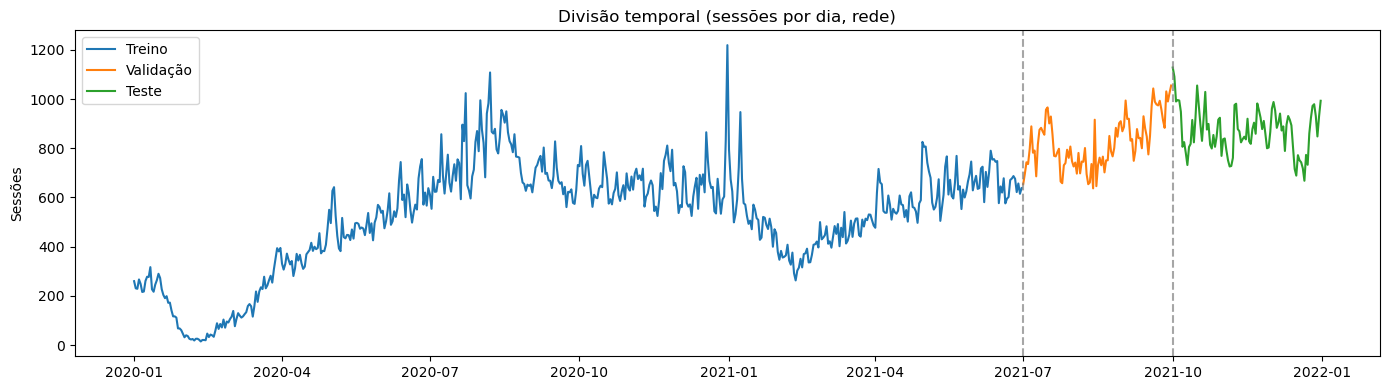

,Treino (desde 01/04/2020),Validação,Teste
Rede,24.8,34.3,36.3
Nanhu,4.3,4.7,4.9
Tongxiang,12.8,16.3,17.4
Xiuzhou,7.7,13.3,14.0


In [27]:
# Divisão temporal (datas definidas na secção 2.1)
train = series.loc[:TRAIN_END]
validation = series.loc[VALIDATION_START:VALIDATION_END]
test = series.loc[TEST_START:TEST_END]

development = pd.concat([train, validation])   # treino + validação (para o modelo final)

# Verificações: os conjuntos não se sobrepõem e cobrem a série toda
assert train.index.max() < validation.index.min()
assert validation.index.max() < test.index.min()
assert len(train) + len(validation) + len(test) == len(series)

for nome, parte in [('Treino', train), ('Validação', validation), ('Teste', test)]:
    print(f'{nome:10s} {parte.index.min():%d/%m/%Y %H:%M} a {parte.index.max():%d/%m/%Y %H:%M} | '
          f'{len(parte):5d} horas ({len(parte) / len(series):.1%}) | {len(parte) // 24} dias')

# Gráfico da divisão (sessões por dia na rede)
diario_rede = series['Rede'].resample('D').sum()
plt.figure(figsize=(14, 4))
plt.plot(diario_rede.loc[:TRAIN_END], label='Treino', color='tab:blue')
plt.plot(diario_rede.loc[VALIDATION_START:VALIDATION_END], label='Validação', color='tab:orange')
plt.plot(diario_rede.loc[TEST_START:TEST_END], label='Teste', color='tab:green')
plt.axvline(pd.Timestamp(VALIDATION_START), color='grey', linestyle='--', alpha=0.7)
plt.axvline(pd.Timestamp(TEST_START), color='grey', linestyle='--', alpha=0.7)
plt.title('Divisão temporal (sessões por dia, rede)')
plt.ylabel('Sessões')
plt.legend()
plt.tight_layout()
plt.show()

# Nível médio de cada série (sessões por hora) em cada conjunto
pd.DataFrame({'Treino (desde 01/04/2020)': series.loc['2020-04-01':TRAIN_END].mean(),
              'Validação': validation.mean(),
              'Teste': test.mean()}).round(1)

### 4.2 Métricas (MAE, RMSE, MASE)

| Métrica | Fórmula | Interpretação |
|---|---|---|
| **MAE** | (1/n) Σ \|y<sub>i</sub> − ŷ<sub>i</sub>\| | Erro médio em sessões; todos os erros pesam o mesmo |
| **RMSE** | √[(1/n) Σ (y<sub>i</sub> − ŷ<sub>i</sub>)²] | Erro em sessões; penaliza mais os erros grandes (ex.: picos) |
| **MASE** | MAE do modelo / MAE do *seasonal naïve* (*m* = 24) no treino | Sem escala: permite comparar a rede com os distritos. MASE < 1 → o modelo é melhor do que a heurística simples |

- O MAE e o RMSE estão nas unidades da série, por isso **não permitem comparar séries com escalas diferentes** (a rede tem cerca de 6 vezes mais sessões do que Nanhu). Para isso usa-se o MASE.
- **O MAPE não é usado:** fica indefinido quando *y* = 0, e as séries têm horas sem sessões (até 15,6% em Nanhu, ver 2.5).

**Período sazonal do MASE: *m* = 24**
- É a sazonalidade dominante: força de 0,906 (2.3) e ACF mais alta no lag 24 (2.4); a sazonalidade semanal é fraca (H13).
- No treino, o *seasonal naïve* com *m* = 24 tem um erro **menor** do que com *m* = 168 em todas as séries (ver tabela abaixo).

**Escala do MASE:** é calculada nos dados de treino do modelo: treino (desde 01/04/2020) para a avaliação na validação, e treino + validação para a avaliação no teste.

**Avaliação por horizonte:** além do valor global, as métricas são calculadas **para cada horizonte *h* = 1, …, 24**, para ver como o erro varia ao longo do dia previsto.

In [28]:
# Funções de avaliação (adaptadas do notebook da aula, sem MAPE)
def mase(y_true, y_pred, y_train, seasonal_period=24):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    reference = np.asarray(y_train, dtype=float).reshape(-1)

    # Erros do seasonal naïve no período de treino
    naive_errors = np.abs(reference[seasonal_period:] - reference[:-seasonal_period])
    scale = np.mean(naive_errors)

    return float(np.mean(np.abs(y_true - y_pred)) / scale)


def forecast_metrics(y_true, y_pred, y_train, seasonal_period=24):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)

    return {
        'MAE': np.mean(np.abs(y_true - y_pred)),
        'RMSE': np.sqrt(np.mean((y_true - y_pred) ** 2)),
        'MASE': mase(y_true, y_pred, y_train, seasonal_period)
    }


# Dados de treino dos modelos (a partir de 01/04/2020, ver 2.6)
train_model = train.loc['2020-04-01':]

# Justificação de m: erro do seasonal naïve no treino com m = 24 e m = 168
escala = {}
for c in series.columns:
    y_c = train_model[c].to_numpy()
    escala[c] = {'m = 24': np.mean(np.abs(y_c[24:] - y_c[:-24])),
                 'm = 168': np.mean(np.abs(y_c[168:] - y_c[:-168]))}

print('MAE do seasonal naïve no treino (sessões por hora):')
pd.DataFrame(escala).T.round(3)

MAE do seasonal naïve no treino (sessões por hora):


,m = 24,m = 168
Rede,6.907,7.470
Nanhu,2.537,2.544
Tongxiang,4.364,4.751
Xiuzhou,3.962,4.041


### 4.3 Baselines

**Conceito: baseline**
Método de previsão muito simples que serve de referência: um modelo só é útil se tiver um erro **menor** do que o da baseline.

Foram usadas as três baselines da aula, adaptadas à formulação da secção 3 (origem às 23:00 do dia D, previsão das 24 horas do dia D+1, só com valores observados até à origem):

| Baseline | Previsão para a hora *t* + *h* |
|---|---|
| **Naive** | Último valor observado: ŷ<sub>t+h</sub> = y<sub>t</sub> (valor das 23:00) |
| **Seasonal Naive (*m* = 24)** | Mesma hora do dia anterior: ŷ<sub>t+h</sub> = y<sub>t+h−24</sub> |
| **Drift** | Último valor + tendência média do histórico: ŷ<sub>t+h</sub> = y<sub>t</sub> + *h* · (y<sub>t</sub> − y<sub>1</sub>) / (*T* − 1) |

O **Seasonal Naive (*m* = 24)** é a **baseline de referência** para a Task 2, porque usa a sazonalidade dominante da série (2.3, 2.4) e é a base do MASE (4.2).

As baselines são avaliadas **apenas na validação** (o teste fica reservado para a avaliação final), com as métricas globais, por horizonte e por mês.

In [29]:
# Baselines com origem às 23:00 de cada dia (só valores observados até à origem)
historico = series.loc['2020-04-01':]                                         # dados a partir de 01/04/2020
ultimo_23h = historico[historico.index.hour == 23]                            # valores das 23:00 (origens)
valor_origem = ultimo_23h.shift(1, freq='h').reindex(historico.index).ffill() # y_t: valor das 23:00 do dia anterior
h = historico.index.hour + 1                                                  # horizonte: 00:00 -> h = 1, ..., 23:00 -> h = 24
n = np.arange(len(historico)) - historico.index.hour                          # nº de observações até à origem
declive = (valor_origem - historico.iloc[0]).div(n - 1, axis=0)

baselines = {
    'Naive': valor_origem,                                   # repete o último valor observado
    'Seasonal Naive (m = 24)': historico.shift(24),          # repete a mesma hora do dia anterior
    'Drift': valor_origem + declive.mul(h, axis=0),          # último valor + tendência média
}

# Avaliação global na validação
linhas = []
for nome, prev in baselines.items():
    for c in series.columns:
        linha = {'Série': c, 'Baseline': nome}
        linha.update(forecast_metrics(validation[c], prev.loc[VALIDATION_START:VALIDATION_END, c], train_model[c]))
        linhas.append(linha)

resultados_val = pd.DataFrame(linhas).set_index(['Série', 'Baseline']).round(3)
resultados_val

,,MAE,RMSE,MASE
Série,Baseline,,,
Rede,Naive,18.401,21.781,2.664
Nanhu,Naive,3.654,4.746,1.440
Tongxiang,Naive,9.164,10.941,2.100
Xiuzhou,Naive,8.529,10.526,2.153
Rede,Seasonal Naive (m = 24),8.196,11.166,1.187
Nanhu,Seasonal Naive (m = 24),2.485,3.529,0.979
Tongxiang,Seasonal Naive (m = 24),5.058,7.126,1.159
Xiuzhou,Seasonal Naive (m = 24),5.316,7.196,1.342
Rede,Drift,18.393,21.773,2.663


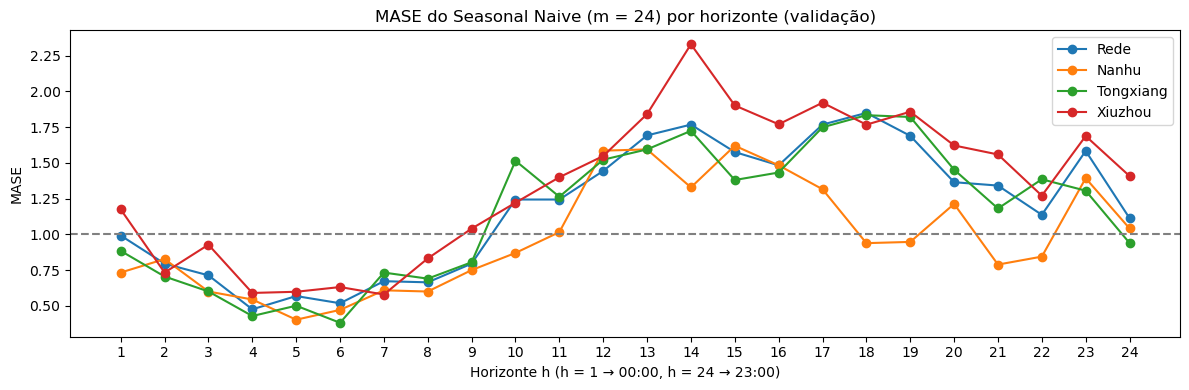

MASE do Seasonal Naive (m = 24) por mês (validação):


,Rede,Nanhu,Tongxiang,Xiuzhou
Julho,1.154,0.881,1.184,1.332
Agosto,1.200,0.845,1.181,1.311
Setembro,1.206,1.220,1.110,1.382


In [30]:
# Seasonal Naive (m = 24): erro por horizonte e por mês na validação
prev_sn = baselines['Seasonal Naive (m = 24)'].loc[VALIDATION_START:VALIDATION_END]
erro_abs = (validation - prev_sn).abs()
escala_mase = {c: np.mean(np.abs(train_model[c].values[24:] - train_model[c].values[:-24])) for c in series.columns}

mase_h = erro_abs.groupby(erro_abs.index.hour + 1).mean() / pd.Series(escala_mase)    # por horizonte
mase_mes = erro_abs.groupby(erro_abs.index.month).mean() / pd.Series(escala_mase)     # por mês
mase_mes.index = ['Julho', 'Agosto', 'Setembro']

fig, ax = plt.subplots(figsize=(12, 4))
mase_h.plot(ax=ax, marker='o')
ax.axhline(1, color='grey', linestyle='--')
ax.set_title('MASE do Seasonal Naive (m = 24) por horizonte (validação)')
ax.set_xlabel('Horizonte h (h = 1 → 00:00, h = 24 → 23:00)')
ax.set_ylabel('MASE')
ax.set_xticks(range(1, 25))
plt.tight_layout()
plt.show()

print('MASE do Seasonal Naive (m = 24) por mês (validação):')
mase_mes.round(3)

In [31]:
# Validar a explicação do MASE > 1: erro relativo (MAE / nível médio) do Seasonal Naive
mae_treino = pd.Series(escala_mase)
mae_val = (validation - prev_sn).abs().mean()

pd.DataFrame({'MAE / nível (treino)': mae_treino / train_model.mean(),
              'MAE / nível (validação)': mae_val / validation.mean()}).round(3)

,MAE / nível (treino),MAE / nível (validação)
Rede,0.279,0.239
Nanhu,0.585,0.533
Tongxiang,0.341,0.310
Xiuzhou,0.517,0.399


**Resultados das baselines na validação**

- **O Seasonal Naive (*m* = 24) é claramente a melhor baseline** em todas as séries (MASE de 0,98 a 1,34, contra 1,44 a 2,66 do Naive e do Drift). Isto confirma que a **sazonalidade diária é dominante** (2.3, 2.4). O Drift é praticamente igual ao Naive, porque em dados horários a tendência média por hora é muito pequena.
- **O MASE do Seasonal Naive é superior a 1** (exceto em Nanhu) porque a escala do MASE é calculada no treino e o **nível da série subiu na validação** (ex.: rede de 24,8 para 34,3 sessões por hora, ver 4.1): com mais sessões, os erros absolutos são maiores. Esta explicação é confirmada pelo erro relativo (MAE / nível médio), que é **menor** na validação do que no treino em todas as séries (ex.: rede 0,279 → 0,239): o método não piorou, os erros absolutos aumentaram porque o volume de sessões aumentou. Nanhu é a exceção porque o seu nível quase não variou (4,3 → 4,7). Por isso, os modelos da Task 2 devem ser comparados com o Seasonal Naive **no mesmo período de avaliação**.
- **Por horizonte:** o erro do Seasonal Naive não aumenta com *h* (usa sempre valores observados). Acompanha a **hora do dia**: é menor de madrugada (*h* ≈ 4–6, poucas sessões) e maior durante a tarde (*h* ≈ 12–19). Como a origem é sempre às 23:00, cada horizonte corresponde a uma hora do dia, e isto tem de ser tido em conta na análise do erro por horizonte dos modelos.
- **Por mês:** o erro é estável na rede, em Tongxiang e em Xiuzhou. Em Nanhu sobe em setembro (0,85 → 1,22), o que coincide com o aumento do nível do distrito nesse mês (de cerca de 100 para cerca de 160 sessões por dia).

**Protocolo para a Task 2:** os modelos candidatos são comparados entre si e com o **Seasonal Naive (*m* = 24)** na validação, com MAE, RMSE e MASE, globalmente, por horizonte, por mês e por série. O modelo escolhido é treinado novamente com treino + validação e avaliado **uma única vez** no teste.

## 5. Síntese final

**1. Qualidade dos dados e construção das séries**

| Achado | Decisão | Secção |
|---|---|---|
| 441 077 transações (2020–2021), agregadas por hora de início | 4 séries horárias (Rede, Nanhu, Tongxiang, Xiuzhou) com 17 544 horas | 1.3 |
| Horas sem sessões | Mantidas como **procura zero real** (sem imputação) | 1.3 |
| Cerca de 12% das transações com 0 kWh | Mantidas (são transações registadas) | 1.2 |
| Período jan–mar 2020 atípico (Ano Novo Chinês + COVID-19) | Análise e modelos a partir de **01/04/2020** | 1.3, 2.6 |
| Interrupções em Nanhu (Technology Park desde 29/09/2021; Tourist Attraction de 14 a 27/12/2021) | Sem imputação; ter em conta na avaliação de Nanhu | 1.3 |
| Meteorologia só registada nas horas com sessões | Não usada como preditor | 1.2, 3.3 |

**2. Principais conclusões da análise exploratória** (período de treino)

| Característica | Conclusão | Secção |
|---|---|---|
| Tendência | Crescente a longo prazo; série não estacionária | 2.1, 2.4 |
| Sazonalidade diária | **Dominante** (força 0,906; ACF no lag 24 = 0,856) e **multiplicativa** | 2.2, 2.3, 2.4 |
| Sazonalidade semanal | **Fraca** (pequena diferença entre dias úteis e fim de semana) | 2.2, 2.4 |
| Diferenças entre distritos | Tendências e pesos diferentes; os distritos menores são mais irregulares (Nanhu: CV 0,97, 15,6% de horas a zero) | 2.5 |
| Padrão diário dos distritos | Forma semelhante (correlação 0,92–0,97); *m* = 24 válido para todos | 2.5 |

**3. Protocolo de previsão e avaliação**

| Elemento | Decisão | Secção |
|---|---|---|
| Emissão | Uma vez por dia, no fim do dia (origem às 23:00) | 3.1 |
| Horizonte | 24 horas do dia seguinte (*h* = 1, …, 24) | 3.1 |
| Séries | Rede e 3 distritos, cada uma com a sua previsão | 3.1 |
| Estratégia multi-step | **Direta** (um modelo por horizonte, sem propagação de erros) | 3.2 |
| Preditores | Últimas 24 horas (lookback *k* = 24), média móvel de 168 horas, dia da semana e fim de semana | 3.3 |
| Variáveis excluídas | Meteorologia (valor futuro não disponível na origem) e atributos das sessões | 3.3 |
| Divisão temporal | Treino até 30/06/2021; validação jul–set 2021; teste out–dez 2021 (usado uma única vez) | 4.1 |
| Métricas | MAE, RMSE e MASE com *m* = 24 (MAPE excluído por causa das horas a zero) | 4.2 |
| Análise do erro | Global, por horizonte, por mês e por série | 4.2, 4.3 |
| Baseline de referência | **Seasonal Naive (*m* = 24)** (MASE na validação: Rede 1,19; Nanhu 0,98; Tongxiang 1,16; Xiuzhou 1,34) | 4.3 |